<a href="https://colab.research.google.com/github/rachmadnanda/MachineLearning2026/blob/main/KMeansEuclidean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import time
import tracemalloc
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

print("Library siap.")

Library siap.


In [2]:
df = pd.read_csv('properti_multi_kota.csv')
print("Shape awal:", df.shape)
df.head()

Shape awal: (64650, 8)


,sumber,lokasi,luas_m2,luas_bangunan,jumlah_kamar,jumlah_kamar_mandi,usia_bangunan,harga
0,uas-properti/Jabodetabek,Tangerang,30.0,NaN,3.0,3.0,33.0,2.037543e+08
1,uas-properti/Jabodetabek,Bekasi,122.0,NaN,5.0,4.0,19.0,1.058032e+09
2,uas-properti/Jabodetabek,Bekasi,142.8,NaN,1.0,1.0,9.0,1.335793e+09
3,uas-properti/Jabodetabek,Bekasi,152.6,NaN,4.0,3.0,6.0,1.613771e+09
4,uas-properti/Jabodetabek,Depok,61.2,NaN,1.0,1.0,9.0,5.221562e+08


In [3]:
# ============================================
# PREPROCESSING UNIVERSAL — dataset baru
# ============================================

# 1. Hapus duplikat (hasil scraping dari banyak sumber)
before = len(df)
df = df.drop_duplicates()
print(f"[1] Hapus duplikat       : {before} -> {len(df)}")

# 2. Hapus outlier & nilai tidak wajar (error scraping)
before = len(df)
df = df[(df['luas_m2'] >= 10) & (df['luas_m2'] <= 2000)]
df = df[(df['luas_bangunan'].isna()) |
        ((df['luas_bangunan'] >= 10) & (df['luas_bangunan'] <= 2000))]
df = df[(df['harga'] >= 50_000_000) & (df['harga'] <= 100_000_000_000)]
df = df[df['jumlah_kamar'].isna() | (df['jumlah_kamar'] <= 20)]
df = df[df['jumlah_kamar_mandi'].isna() | (df['jumlah_kamar_mandi'] <= 20)]
print(f"[2] Hapus outlier        : {before} -> {len(df)}")

# 3. Perbaiki usia_bangunan: sebagian sumber menyimpan TAHUN bangunan
#    (misal 2020), bukan usia. Nilai > 100 dikonversi: usia = 2026 - tahun.
mask_tahun = df['usia_bangunan'] > 100
df.loc[mask_tahun, 'usia_bangunan'] = 2026 - df.loc[mask_tahun, 'usia_bangunan']
df.loc[~df['usia_bangunan'].between(0, 100) & df['usia_bangunan'].notna(),
       'usia_bangunan'] = np.nan
print(f"[3] Konversi tahun->usia : {mask_tahun.sum()} baris dikonversi")

# 4. Isi missing values dengan median
FEATURES = ['luas_m2', 'luas_bangunan', 'jumlah_kamar',
            'jumlah_kamar_mandi', 'usia_bangunan', 'harga']
for col in FEATURES:
    df[col] = df[col].fillna(df[col].median())
print(f"[4] Missing values diisi : {df[FEATURES].isnull().sum().sum()} tersisa")

# 5. Sampling 15.000 data (reproducible) — dataset asli ~57 ribu,
#    sampling diperlukan agar semua metode (terutama Hierarchical & DBSCAN)
#    tetap layak dijalankan.
df = df.sample(n=15000, random_state=42).reset_index(drop=True)
print(f"[5] Sampling             : 15.000 data (random_state=42)")

# 6. Scaling
X = df[FEATURES].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"[6] Data siap clustering : {X_scaled.shape}")
print(f"[7] Fitur                : {FEATURES}")

[1] Hapus duplikat       : 64650 -> 57494
[2] Hapus outlier        : 57494 -> 56170
[3] Konversi tahun->usia : 2757 baris dikonversi
[4] Missing values diisi : 0 tersisa
[5] Sampling             : 15.000 data (random_state=42)
[6] Data siap clustering : (15000, 6)
[7] Fitur                : ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi', 'usia_bangunan', 'harga']


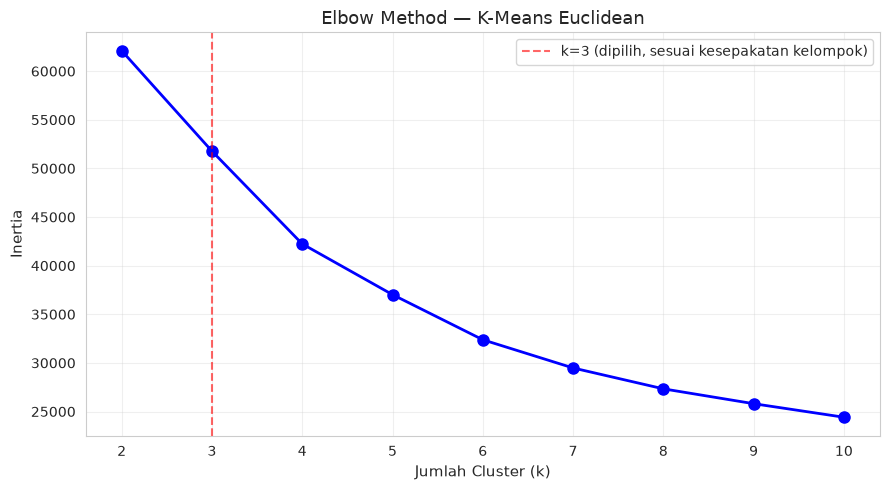

Nilai inertia per k:
  k=2: 62107.12
  k=3: 51775.49
  k=4: 42235.86
  k=5: 37020.34
  k=6: 32381.49
  k=7: 29480.23
  k=8: 27333.83
  k=9: 25806.15
  k=10: 24413.53


In [4]:
# Coba k = 2 sampai 10
K_RANGE = range(2, 11)
inertia = []

for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

# Plot Elbow
plt.figure(figsize=(9, 5))
plt.plot(K_RANGE, inertia, 'bo-', linewidth=2, markersize=8)
plt.axvline(x=3, color='red', linestyle='--', alpha=0.6,
            label='k=3 (dipilih, sesuai kesepakatan kelompok)')
plt.xlabel('Jumlah Cluster (k)', fontsize=11)
plt.ylabel('Inertia', fontsize=11)
plt.title('Elbow Method — K-Means Euclidean', fontsize=13)
plt.xticks(K_RANGE)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Nilai inertia per k:")
for k, i in zip(K_RANGE, inertia):
    print(f"  k={k}: {i:.2f}")

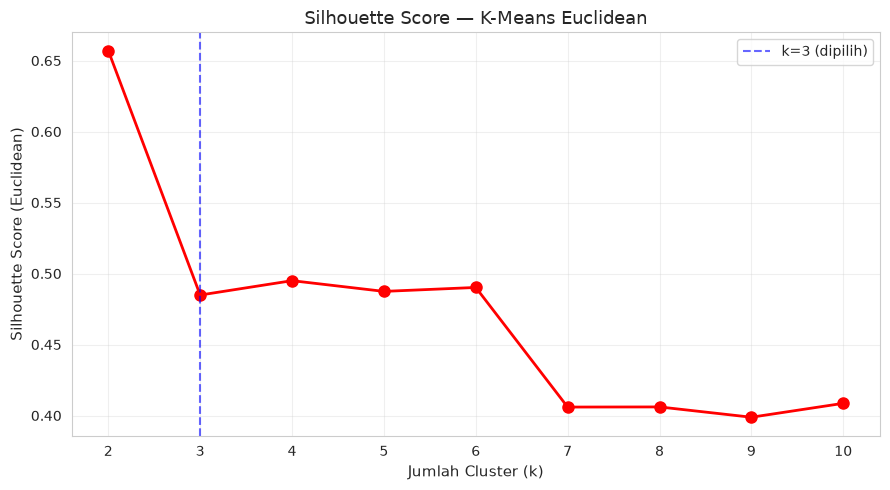

Silhouette Score per k:
  k=2: 0.6570
  k=3: 0.4849
  k=4: 0.4950
  k=5: 0.4875
  k=6: 0.4902
  k=7: 0.4060
  k=8: 0.4061
  k=9: 0.3988
  k=10: 0.4086

>> Silhouette tertinggi: k=2.
>> Tetap dipakai k=3 sesuai kesepakatan kelompok (fair comparison antar metode).


In [5]:
sil_scores = []

for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_tmp = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels_tmp, metric='euclidean')
    sil_scores.append(score)

plt.figure(figsize=(9, 5))
plt.plot(K_RANGE, sil_scores, 'ro-', linewidth=2, markersize=8)
plt.axvline(x=3, color='blue', linestyle='--', alpha=0.6,
            label='k=3 (dipilih)')
plt.xlabel('Jumlah Cluster (k)', fontsize=11)
plt.ylabel('Silhouette Score (Euclidean)', fontsize=11)
plt.title('Silhouette Score — K-Means Euclidean', fontsize=13)
plt.xticks(K_RANGE)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Silhouette Score per k:")
for k, s in zip(K_RANGE, sil_scores):
    print(f"  k={k}: {s:.4f}")

print(f"\n>> Silhouette tertinggi: k={list(K_RANGE)[np.argmax(sil_scores)]}.")
print(">> Tetap dipakai k=3 sesuai kesepakatan kelompok (fair comparison antar metode).")

In [6]:
# ============================================
# PARAMETER
# ============================================
K_OPTIMAL = 3  # sesuai kesepakatan kelompok (fair comparison)

# Tracking
tracemalloc.start()
start_time = time.time()

# Training
kmeans = KMeans(n_clusters=K_OPTIMAL, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)

exec_time = time.time() - start_time
_, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

df['cluster'] = labels

print("="*55)
print("HASIL K-MEANS (EUCLIDEAN)")
print("="*55)
print(f"Jumlah cluster       : {K_OPTIMAL}")
print(f"Inertia              : {kmeans.inertia_:.2f}")
print(f"Waktu eksekusi       : {exec_time:.4f} detik")
print(f"Peak memory          : {peak/1024:.2f} KB")
print("\nDistribusi cluster:")
print(df['cluster'].value_counts().sort_index())

HASIL K-MEANS (EUCLIDEAN)
Jumlah cluster       : 3
Inertia              : 51775.49
Waktu eksekusi       : 0.3944 detik
Peak memory          : 2128.83 KB

Distribusi cluster:
cluster
0    10905
1      629
2     3466
Name: count, dtype: int64


In [7]:
print("Rata-rata fitur per cluster:")
print(df.groupby('cluster')[FEATURES].mean().round(2))

Rata-rata fitur per cluster:
         luas_m2  luas_bangunan  jumlah_kamar  jumlah_kamar_mandi  \
cluster                                                             
0         102.20          63.16          2.09                1.35   
1         889.72         579.15          5.98                4.54   
2         224.83         186.05          3.99                3.21   

         usia_bangunan         harga  
cluster                               
0                 9.94  7.506549e+08  
1                11.15  1.147091e+10  
2                11.23  2.518426e+09  


In [8]:
print("\nDistribusi lokasi per cluster (10 lokasi terbanyak):")
top_lokasi = df['lokasi'].value_counts().head(10).index
print(pd.crosstab(df['cluster'], df.loc[df['lokasi'].isin(top_lokasi), 'lokasi']))

print("\nDistribusi sumber data per cluster (10 sumber terbanyak):")
top_sumber = df['sumber'].value_counts().head(10).index
print(pd.crosstab(df['cluster'], df.loc[df['sumber'].isin(top_sumber), 'sumber']))


Distribusi lokasi per cluster (10 lokasi terbanyak):
lokasi   Bekasi  Depok  Kabupaten Bandung  Kabupaten Bekasi  Kabupaten Bogor  \
cluster                                                                        
0           366    261                383               423              492   
1             3      1                  0                 0                0   
2           128    125                 29                36               36   

lokasi   Kabupaten Sidoarjo  Kabupaten Tangerang  Semarang  Surabaya  \
cluster                                                                
0                       397                  343       266       219   
1                         1                    0        17        57   
2                        33                  110        69       164   

lokasi   Tangerang Selatan  
cluster                     
0                      261  
1                        4  
2                      171  

Distribusi sumber data per cluster (10

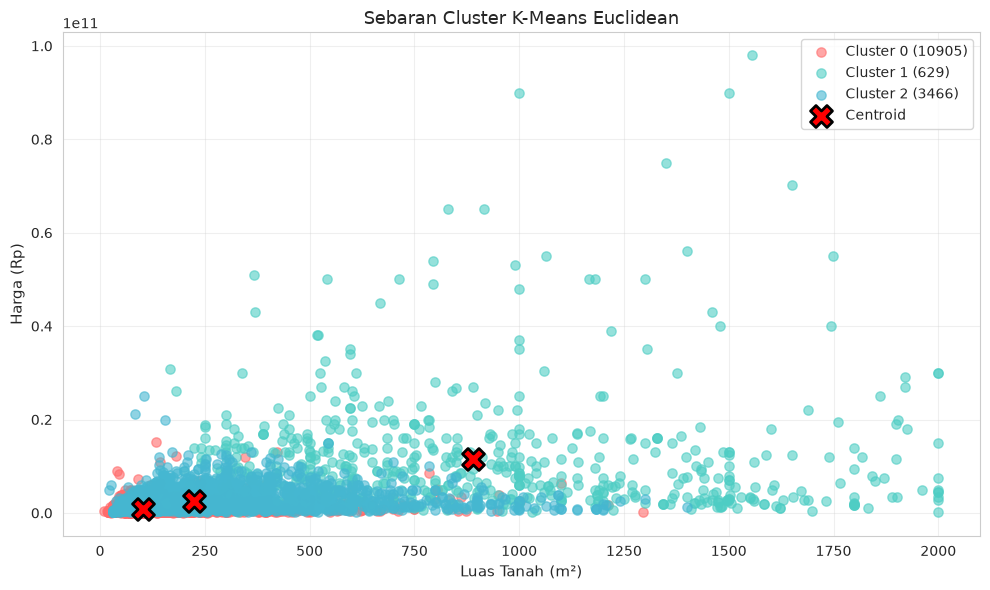

In [9]:
plt.figure(figsize=(10, 6))

# Warna per cluster
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7',
          '#DDA0DD', '#F0E68C', '#87CEEB', '#FFB6C1']

for i, label in enumerate(sorted(df['cluster'].unique())):
    subset = df[df['cluster'] == label]
    plt.scatter(subset['luas_m2'], subset['harga'],
                s=45, alpha=0.6, c=colors[i % len(colors)],
                label=f'Cluster {label} ({len(subset)})')

# Plot centroid (dalam skala asli — inverse transform)
centroids_scaled = kmeans.cluster_centers_
centroids_orig = scaler.inverse_transform(centroids_scaled)
idx_luas = FEATURES.index('luas_m2')
idx_harga = FEATURES.index('harga')
plt.scatter(centroids_orig[:, idx_luas], centroids_orig[:, idx_harga],
            c='red', marker='X', s=250, edgecolor='black',
            linewidth=2, label='Centroid', zorder=5)

plt.xlabel('Luas Tanah (m²)', fontsize=11)
plt.ylabel('Harga (Rp)', fontsize=11)
plt.title('Sebaran Cluster K-Means Euclidean', fontsize=13)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
sil_final = silhouette_score(X_scaled, df['cluster'], metric='euclidean')
print(f"Silhouette Score Final (Euclidean): {sil_final:.4f}")

Silhouette Score Final (Euclidean): 0.4849


In [11]:
hasil_kmeans_euclidean = {
    'Metode'              : 'K-Means',
    'Distance Metric'     : 'Euclidean',
    'Jumlah Cluster'      : K_OPTIMAL,
    'Jumlah Noise'        : 0,
    'Waktu Eksekusi (s)'  : round(exec_time, 4),
    'Peak Memory (KB)'    : round(peak / 1024, 2),
    'Silhouette Score'    : round(sil_final, 4),
    'Parameter'           : f'k={K_OPTIMAL}'
}

tabel = pd.DataFrame([hasil_kmeans_euclidean])
print("="*60)
print("RINGKASAN METRIK — K-MEANS EUCLIDEAN")
print("="*60)
tabel.T

RINGKASAN METRIK — K-MEANS EUCLIDEAN


,0
Metode,K-Means
Distance Metric,Euclidean
Jumlah Cluster,3
Jumlah Noise,0
Waktu Eksekusi (s),0.3944
Peak Memory (KB),2128.83
Silhouette Score,0.4849
Parameter,k=3
